## A combinação NumPy, Pandas e Scikit-Learn é muito poderosa

Embora O Scikit-Learn seja responsável por facilitar grande parte do pipeline de Machine Learning, dois componentes são essenciais para ler arquivos e manipular as informações: NumPy e Pandas. O NumPy auxilia a manipulação matricial dos dados, que é fundamental para aprendizado de máquina; enquanto o Pandas atua como um facilitador para a manipulação de dados de forma menos estruturada.

*Esse conteúdo é baseado no capítulo 'Machine Learning' de Numerical Python, segunda edição, de Robert Johannson.*

A seguir é utilizado o comando read_csv do Pandas para ter acesso aos dados do arquivo 'energy_data.csv', e o comando *describe* gera um sumário dos dados quando possível. A nomenclatura df para a variável vem de DataFrame do Pandas, mas poderia ser o nome que o programador quisesse dar.

In [1]:
import pandas as pd

df = pd.read_csv('energy_data.csv')
df.describe()
df

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.890000,47.596667,19.200000,44.790000,19.790000,44.730000,19.000000,...,17.033333,45.530000,6.600000,733.500000,92.000000,7.000000,63.000000,5.300000,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.890000,46.693333,19.200000,44.722500,19.790000,44.790000,19.000000,...,17.066667,45.560000,6.483333,733.600000,92.000000,6.666667,59.166667,5.200000,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.890000,46.300000,19.200000,44.626667,19.790000,44.933333,18.926667,...,17.000000,45.500000,6.366667,733.700000,92.000000,6.333333,55.333333,5.100000,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.890000,46.066667,19.200000,44.590000,19.790000,45.000000,18.890000,...,17.000000,45.400000,6.250000,733.800000,92.000000,6.000000,51.500000,5.000000,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.890000,46.333333,19.200000,44.530000,19.790000,45.000000,18.890000,...,17.000000,45.400000,6.133333,733.900000,92.000000,5.666667,47.666667,4.900000,10.084097,10.084097
5,2016-01-11 17:50:00,50,40,19.890000,46.026667,19.200000,44.500000,19.790000,44.933333,18.890000,...,17.000000,45.290000,6.016667,734.000000,92.000000,5.333333,43.833333,4.800000,44.919484,44.919484
6,2016-01-11 18:00:00,60,50,19.890000,45.766667,19.200000,44.500000,19.790000,44.900000,18.890000,...,17.000000,45.290000,5.900000,734.100000,92.000000,5.000000,40.000000,4.700000,47.233763,47.233763
7,2016-01-11 18:10:00,60,50,19.856667,45.560000,19.200000,44.500000,19.730000,44.900000,18.890000,...,17.000000,45.290000,5.916667,734.166667,91.833333,5.166667,40.000000,4.683333,33.039890,33.039890
8,2016-01-11 18:20:00,60,40,19.790000,45.597500,19.200000,44.433333,19.730000,44.790000,18.890000,...,17.000000,45.290000,5.933333,734.233333,91.666667,5.333333,40.000000,4.666667,31.455702,31.455702
9,2016-01-11 18:30:00,70,40,19.856667,46.090000,19.230000,44.400000,19.790000,44.863333,18.890000,...,17.000000,45.290000,5.950000,734.300000,91.500000,5.500000,40.000000,4.650000,3.089314,3.089314


Esse conjunto de dados está disponível em https://archive.ics.uci.edu/ml/datasets/Appliances+energy+prediction# e um Github do artigo que originou essa contribuição está disponível em https://github.com/LuisM78/Appliances-energy-prediction-data.

O objetivo é utilizar as informações de clima fora e dentro de uma casa para estimar o consumo de energia elétrico que aquela casa, naquelas condições meteorológicas, demandaria. Portanto, serão considerados atributos todas as colunas exceto Appliace, e essa coluna será utilizada como *target*.

In [2]:
X = df.drop(['Appliances','date'],axis=1)
y = df.Appliances

In [3]:
print(X.shape)
print(y.shape)

(19735, 27)
(19735,)


São 27 atributos que farão a composição de X, e o total de amostras são 19735. Por se tratar de um problema de regressão, serão importados os módulos do Scikit-Learn para a separação dos dados e a geração dos regressores (modelos de regressão). Em seguida, os dados são separados com o comando *train_test_split* e um modelo de Regressão Linear é treinado com a função *fit*.

**Vamos supor um cenário com 20 amostras do conjunto inicial para propósitos didáticos:**

In [4]:
from sklearn import model_selection
from sklearn import linear_model

X_train, X_test, y_train, y_test = model_selection.train_test_split(X[:20], y[:20], test_size=0.5, random_state=42)
model = linear_model.LinearRegression()

model.fit(X_train, y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=1, normalize=False)

Em seguida, é importante calcular o resíduo entre o que o modelo diz e o que de fato é. Esse resíduo também pode ser acumulado como erro utilizando alguma função. Vamos verificar então qual é o erro para o próprio conjunto de treino utilizando o erro quadrático médio, e depois o erro no teste.

In [5]:
from sklearn import metrics

erro_treino = metrics.mean_squared_error(y_train,model.predict(X_train))
print('RMSE no treino:', erro_treino)

erro_teste = metrics.mean_squared_error(y_test,model.predict(X_test))
print('RMSE no teste:', erro_teste)

RMSE no treino: 1.257314531080602e-23
RMSE no teste: 11026.711166531906


É possível perceber que o erro no treino é muito baixo, praticamente zero, enquanto que o erro no teste é bastante alto (> 10k). Isso se deve a um fenômeno chamado **overfitting**. É muito comum que, quando o número de atributos seja maior que o número de amostras, a regressão fique sobreajustada (overfit) para os dados de treino, e não generaliza suficiente para o conjunto de teste.

Outra forma de analisar o resultado de uma regressão é calculando o **r²-score** pela função score do modelo de regressão:

In [6]:
r2 = model.score(X_train, y_train)
print('r² no treino:', r2)

r2 = model.score(X_test, y_test)
print('r² no teste:', r2)

import sklearn
print(sklearn.__version__)

r² no treino: 1.0
r² no teste: 0.5359128296914181
0.19.1


Os resultados novamente indicam sobreajustamento, dado que o r² no treino é 1.0 (máximo) e o r² no teste é baixo (metade).

Por último, também é possível visualizar essa diferença de forma gráfica. Compara-se o resíduo por amostra tanto no treino quanto no teste, e observa-se os coeficientes encontrados:

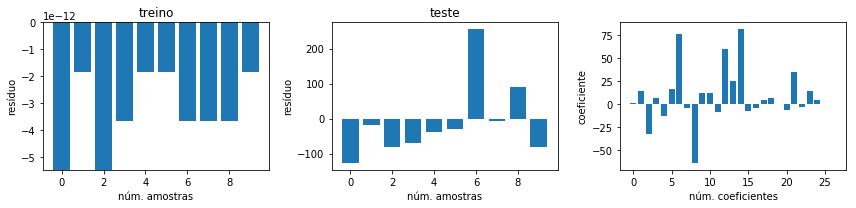

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import seaborn as sns

def plot_residuals_and_coeff(resid_train, resid_test, coeff):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    axes[0].bar(np.arange(len(resid_train)), resid_train)
    axes[0].set_xlabel("núm. amostras")
    axes[0].set_ylabel("resíduo")
    axes[0].set_title("treino")
    axes[1].bar(np.arange(len(resid_test)), resid_test)
    axes[1].set_xlabel("núm. amostras")
    axes[1].set_ylabel("resíduo")
    axes[1].set_title("teste")
    axes[2].bar(np.arange(len(coeff)), coeff)
    axes[2].set_xlabel("núm. coeficientes")
    axes[2].set_ylabel("coeficiente")
    fig.tight_layout()
    return fig, axes

residuo_treino = y_train - model.predict(X_train)
residuo_teste  = y_test - model.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, model.coef_)
#escalas muito diferentes

É possível perceber nas escalas dos resíduos que os erros são muito maiores no conjunto de teste do que no conjunto de treino. *Uma das formas de corrigir esse problema é aplicando regularização*, forçando os coeficientes a residirem num espaço próximo. As duas normais mais comuns de regularização são L1 e L2, respectivamente LASSO e Ridge. Enquanto que L2 favorece com coeficientes menores, L1 favorece modelos que têm poucos coeficientes próximos de zero.


**Quando usar L1 ou L2?**

* L1: Deseja-se eliminar o maior número de atributos que não contribuem com o problema;ele não tira ele zera no gráfico por causa da conta
* L2: Limitar a magnitude dos coeficientes do modelo,para não ter um atributo que impacta demais

**Utilizando Ridge — L2**

In [8]:
model = linear_model.Ridge(alpha=2.5)
model.fit(X_train, y_train)

erro_treino = metrics.mean_squared_error(y_train,model.predict(X_train))
print('RMSE no treino:', erro_treino)

erro_teste = metrics.mean_squared_error(y_test,model.predict(X_test))
print('RMSE no teste:', erro_teste)

RMSE no treino: 600.2516931383146
RMSE no teste: 9577.387704962166


O erro no treino não é mais próximo a zero, mas é possível perceber que *o erro no teste diminuiu*. Vale lembrar que os dados do teste são mais parecidos com os dados do mundo real, ou seja, são informações que o modelo não teve acesso, portanto mais difíceis de serem previstas corretamente.

Graficamente, é possível perceber uma mudança nos pesos também:

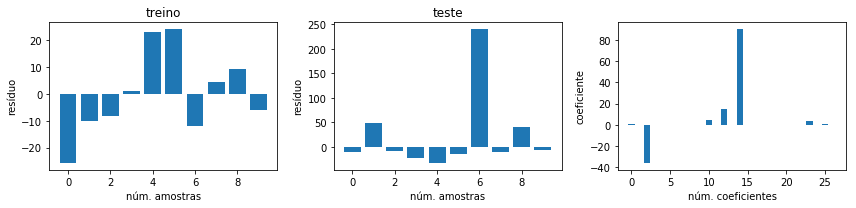

In [14]:
residuo_treino = y_train - model.predict(X_train)
residuo_teste  = y_test - model.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, model.coef_)

In [16]:
residuo_teste

0     -10.622373
17     48.049221
15     -8.209753
1     -21.972916
8     -32.910714
5     -13.471740
11    240.050672
3      -9.668060
18     40.429201
16     -6.842821
Name: Appliances, dtype: float64

**Utilizando LASSO — L1**

In [10]:
model = linear_model.Lasso(alpha=2.5)
model.fit(X_train, y_train)

erro_treino = metrics.mean_squared_error(y_train,model.predict(X_train))
print('RMSE no treino:', erro_treino)

erro_teste = metrics.mean_squared_error(y_test,model.predict(X_test))
print('RMSE no teste:', erro_teste)

RMSE no treino: 247.0044650105414
RMSE no teste: 6215.444871282403


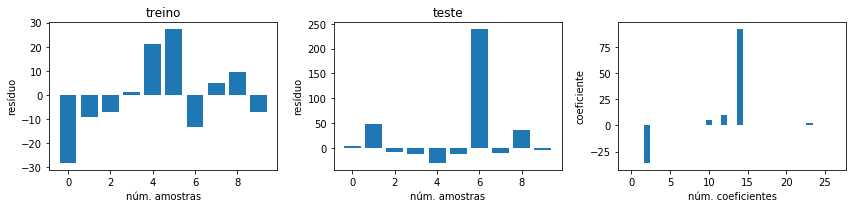

In [11]:
residuo_treino = y_train - model.predict(X_train)
residuo_teste  = y_test - model.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, model.coef_)

Os resultados de erro no treino são mais baixos que do Ridge, porém mais altos que a regressão linear sem regularização, porém o erro no teste caiu aproximadamente para a metade. Também é possível perceber que L1 reduziu significativamente o número de atributos que, de fato, contribuem para a solução do problema.

Também é possível perceber que o **parâmetro alpha é configurável**, portanto é importante fazer uma varredura para identificar qual seria o melhor valor.

## Exercícios

1. **Faça a busca de melhor parâmetro de alpha para reduzir o erro quadrático médio nessa base de apenas 20 amostras, considerando L1 e L2. Considere utilizar as funções LassoCV e RidgeCV, e busque informações sobre elas na documentação do Scikit-Learn.**


2. **Recarregue a base e não filtre apenas 20 amostras e aplique os modelos de regressão vistos. Tenha um olhar crítico para os seguintes questionamentos após codificar e ver os resultados:**
    * Qual regressão teve o melhor resultado?
    * Há algum sinal de overfitting?
    * Todos atributos são relevantes para o problema?
    * Todos coeficientes estão em uma mesma magnitude?

In [12]:
from sklearn import model_selection
from sklearn import linear_model

X_train, X_test, y_train, y_test = model_selection.train_test_split(X[:20], y[:20], test_size=0.5, random_state=42)
model = linear_model.LinearRegression()

model.fit(X_train, y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=1, normalize=False)

In [13]:
import numpy as np
for i in range(1,10):
    model = linear_model.LassoCV(alphas=np.arange(1,10^i))
    #model = linear_model.RidgeCV(alphas=np.arange(0.1,10,0.1))
    model.fit(X_train, y_train)

    erro_treino = metrics.mean_squared_error(y_train,model.predict(X_train))
    print('RMSE no treino:', erro_treino)

    erro_teste = metrics.mean_squared_error(y_test,model.predict(X_test))
    print('RMSE no teste:', erro_teste)

alpha=model.alpha_
print('Best Alpha: ', round(alpha,2))

RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 373.1284142610195
RMSE no teste: 6232.823246371299
RMSE no treino: 132.55743636926758
RMSE no teste: 5692.162408544989
RMSE no treino: 223.93165396088844
RMSE no teste: 6363.551524901314
Best Alpha:  2


C:\Users\Diniz\Anaconda3\lib\site-packages\sklearn\linear_model\coordinate_descent.py:491: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Fitting data with very small alpha may cause precision problems.
  ConvergenceWarning)
C:\Users\Diniz\Anaconda3\lib\site-packages\sklearn\linear_model\coordinate_descent.py:491: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Fitting data with very small alpha may cause precision problems.
  ConvergenceWarning)
C:\Users\Diniz\Anaconda3\lib\site-packages\sklearn\linear_model\coordinate_descent.py:491: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Fitting data with very small alpha may cause precision problems.
  ConvergenceWarning)
